# Brandstofprijsvolatiliteit Analyse
## Crunchr Airlines - PLANE Project

**Auteur:** Jannes Holdinga
**Datum:** Oktober 2026
**Challenge:** Strategic Business Challenge 2 - Fuel Price Volatility

Dit notebook analyseert de brandstofprijsvolatiliteit van Crunchr Airlines over 2023-2024. Het doel is inzicht te geven in prijsschommelingen, kosten per vliegtuigtype en route, en de financiële impact van mogelijke prijsstijgingen.

## Overzicht van de vier modellen

Dit notebook bevat de vier modellen die we voor Crunchr Airlines hebben gebouwd. Per model staan de **werking**, het **resultaat** en de **conclusie** direct na de code.

| Nr | Model | Doel | Oordeel |
|---|---|---|---|
| 1 | ARIMA op maandgemiddelden (sectie 9) | Maandprijs voorspellen | Niet bruikbaar |
| 2 | Random forest classificatie op vluchten (sectie 10 en 11) | Duur of goedkoop per vlucht | Schijnbaar goed, maar niet bruikbaar |
| 3 | Classificatie voor hedging op maandniveau (sectie 12) | Signaal voor afdekking | Zwak signaal, niet bruikbaar |
| 4 | ARIMA op dagprijzen met halfjaarlijkse golf (sectie 13) | Dagprijs 180 dagen vooruit | Bruikbaar als basislijn, met grote marge |

*Let op: in de inleescel staat het datapad van de auteur (`~/Desktop/...`). Pas dat aan naar de map waarin `flights.csv` staat.*

In [55]:
# Stap 1: Libraries installeren
!pip install pandas matplotlib seaborn numpy

In [56]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


In [57]:
import os

data_map = os.path.expanduser("~/Desktop/Data Driven business /Alle chruncr data")

for bestand in os.listdir(data_map):
    print(bestand)

20260911 - Crunchr Airlines Financial information 2025 (2).pdf
~$vies challange 2 .docx
~$MO 16 okt lisa.docx
MÉMO 16 okt lisa.docx
Data kijken.ipynb
Advies_voorspellend_model_brandstofprijsrisico_Crunchr.docx
aircraft_types.csv
Introductory meetings by Lisa Leenders (1).docx
FAIR_controle_Crunchr.ipynb
routes.csv
crunchr_esb_logs (1).csv
202608 - Contract Crunchr Airlines - IAT - PLANE - Project Leveraging Analytics for New Endeavors - VT (1).pdf
crunchr_boekingsdata (1).csv
fair_rapport.csv
Advies challange 2 .docx
Crunchr_data_met_conclusies.ipynb
disruptions.csv
maintenance_events.csv
Crunchr data.ipynb
datadictionary_sjabloon.csv
20260911 - Additional Data Crunch Airlines (1).xlsx
flights.csv
processed
Architecture diagram Crunchr Airlines (1).docx


In [58]:
# Hoofdbestand inladen
flights = pd.read_csv(data_map + "/flights.csv")

# Eerste 5 rijen bekijken
flights.head()

,vlucht_id,datum,route_id,van,naar,vliegtuigtype,registratie,naam_toestel,block_uren,brandstof_kg,brandstof_kg_per_uur,brandstofprijs_eur_per_kg,brandstofkost_eur,vertraging_min,status,reden,omleiding_naar
0,FL5001,2023-01-01,RT-AMS-LHR,Amsterdam,Londen,Boeing 737 MAX 8,PH-CR106,Xihoumen,1.29,3157.0,2449.0,0.989,3122.28,21,completed,NaN,NaN
1,FL5002,2023-01-01,RT-AMS-LHR,Amsterdam,Londen,Airbus A220-300,PH-CR176,Dolphin,1.37,3067.4,2246.3,0.989,3033.64,135,completed,NaN,NaN
2,FL5003,2023-01-01,RT-AMS-LHR,Amsterdam,Londen,Airbus A220-300,PH-CR172,Linden,1.36,3055.2,2248.1,0.989,3021.59,0,completed,NaN,NaN
3,FL5004,2023-01-01,RT-AMS-LHR,Amsterdam,Londen,Airbus A319,PH-CR165,Nasturtium,1.33,7182.7,5383.2,0.989,7103.66,0,completed,NaN,NaN
4,FL5005,2023-01-01,RT-AMS-LHR,Amsterdam,Londen,Airbus A321,PH-CR142,Hellebore,1.31,5953.3,4543.8,0.989,5887.84,0,completed,NaN,NaN


## 1. Data inladen en verkennen

In [59]:
# Overzicht van de dataset
print(f"Aantal rijen: {len(flights)}")
print(f"Aantal kolommen: {len(flights.columns)}")
print()
print("Kolommen en datatypes:")
print(flights.dtypes)

Aantal rijen: 16060
Aantal kolommen: 17

Kolommen en datatypes:
vlucht_id                     object
datum                         object
route_id                      object
van                           object
naar                          object
vliegtuigtype                 object
registratie                   object
naam_toestel                  object
block_uren                   float64
brandstof_kg                 float64
brandstof_kg_per_uur         float64
brandstofprijs_eur_per_kg    float64
brandstofkost_eur            float64
vertraging_min                 int64
status                        object
reden                         object
omleiding_naar                object
dtype: object


In [60]:
# Datum omzetten naar datetime
flights['datum'] = pd.to_datetime(flights['datum'])

# Check
print(f"Eerste datum: {flights['datum'].min()}")
print(f"Laatste datum: {flights['datum'].max()}")

Eerste datum: 2023-01-01 00:00:00
Laatste datum: 2024-12-30 00:00:00


### ETL: kwaliteitscheck, transformatie en opslag

Voordat we de data analyseren, zetten we die eerst op één plek klaar volgens de ETL-principes (Extract, Transform, Load). Zo werken alle analyses en modellen in dit notebook met dezelfde gecontroleerde dataset.

- **Extract:** de vluchtdata wordt ingeladen uit `flights.csv` (zie de cellen hierboven).
- **Transform:** we controleren de data op ontbrekende waarden, dubbele vluchten en dagen met meer dan één brandstofprijs. Daarna voegen we de afgeleide kolommen `maand`, `jaar` en `maand_nr` toe, die in de rest van het notebook gebruikt worden.
- **Load:** de opgeschoonde dataset wordt opgeslagen als `processed/flights_clean.csv`. Daardoor is de basis voor de analyse reproduceerbaar en hoeft die niet steeds opnieuw opgebouwd te worden.

In [61]:
print(flights.isna().sum())
print("Dubbele vluchten:", flights.duplicated('vlucht_id').sum())
print("Dagen met meer dan één prijs:",
      (flights.groupby('datum')['brandstofprijs_eur_per_kg'].nunique() > 1).sum())

vlucht_id                        0
datum                            0
route_id                         0
van                              0
naar                             0
vliegtuigtype                    0
registratie                      0
naam_toestel                     0
block_uren                       0
brandstof_kg                     0
brandstof_kg_per_uur             0
brandstofprijs_eur_per_kg        0
brandstofkost_eur                0
vertraging_min                   0
status                           0
reden                        15655
omleiding_naar               15809
dtype: int64
Dubbele vluchten: 0
Dagen met meer dan één prijs: 0


De kwaliteitscheck laat zien dat de dataset compleet is: er zijn geen dubbele vluchten en elke dag heeft precies één brandstofprijs. Alleen `reden` en `omleiding_naar` hebben lege waarden. Dat is logisch, want die kolommen zijn alleen ingevuld bij vluchten met een verstoring of omleiding. We laten ze daarom leeg en verwijderen geen rijen.

In [62]:
# Transform: afgeleide kolommen voor de rest van het notebook
flights['maand'] = flights['datum'].dt.to_period('M')
flights['jaar'] = flights['datum'].dt.year
flights['maand_nr'] = flights['datum'].dt.month

In [63]:
os.makedirs("processed", exist_ok=True)
flights.to_csv("processed/flights_clean.csv", index=False)

## 2. Brandstofprijs basiscijfers


In [64]:
# Basiscijfers brandstofprijs
prijs = flights['brandstofprijs_eur_per_kg']

print("=== Brandstofprijs (EUR per kg) ===")
print(f"Gemiddeld:  €{prijs.mean():.4f}")
print(f"Laagste:    €{prijs.min():.4f}")
print(f"Hoogste:    €{prijs.max():.4f}")
print(f"Verschil:   €{prijs.max() - prijs.min():.4f}")

=== Brandstofprijs (EUR per kg) ===
Gemiddeld:  €0.8815
Laagste:    €0.7436
Hoogste:    €1.0194
Verschil:   €0.2758


In het tabel hier boven is zijn de verschillende brandstofprijzen weergegeven

## 3. Prijstrend over tijd

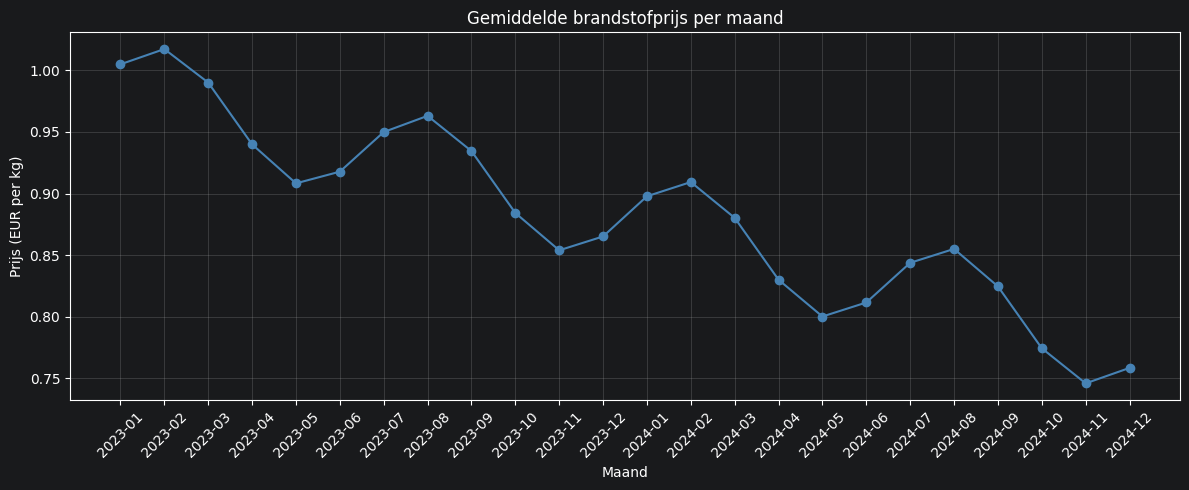

In [65]:
# Maandelijkse gemiddelde brandstofprijs
flights['maand'] = flights['datum'].dt.to_period('M')
maand_prijs = flights.groupby('maand')['brandstofprijs_eur_per_kg'].mean()

# Grafiek
plt.figure(figsize=(12, 5))
plt.plot(maand_prijs.index.astype(str), maand_prijs.values, marker='o', color='steelblue')
plt.title('Gemiddelde brandstofprijs per maand')
plt.ylabel('Prijs (EUR per kg)')
plt.xlabel('Maand')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

De grafiek toont een dalende trend in de gemiddelde brandstofprijs over 2023 en 2024. Begin 2023 bereikte de prijs een piek van ruim €1,01 per kilogram, terwijl eind 2024 de prijs was gedaald naar circa €0,75. Ondanks deze dalende trend zijn er duidelijke schommelingen zichtbaar, zoals de stijging rond augustus 2023 en juli 2024. Deze schommelingen maken het voor Crunchr Airlines lastig om brandstofkosten nauwkeurig te budgetteren, zelfs wanneer de algemene trend gunstig is. Voor het board is het belangrijk te begrijpen dat een dalende trend geen garantie biedt voor stabiliteit in de toekomst.

In [66]:
# Totale brandstofkosten
totaal = flights['brandstofkost_eur'].sum()
print(f"Totale brandstofkosten (2023-2024): €{totaal:,.0f}")

# Per jaar
flights['jaar'] = flights['datum'].dt.year
per_jaar = flights.groupby('jaar')['brandstofkost_eur'].sum()
for jaar, kosten in per_jaar.items():
    print(f"  {jaar}: €{kosten:,.0f}")

Totale brandstofkosten (2023-2024): €200,425,403
  2023: €106,451,562
  2024: €93,973,841


## 4. Scenario-analyse

In [67]:
# Scenario-analyse: wat als de brandstofprijs stijgt?
kosten_2024 = per_jaar[2024]

scenarios = [10, 20, 30, 50]

print("=== Scenario-analyse op basis van 2024 ===")
print(f"Huidige kosten 2024: €{kosten_2024:,.0f}")
print()
for pct in scenarios:
    extra = kosten_2024 * (pct / 100)
    print(f"+{pct}% prijsstijging: €{extra:,.0f} extra kosten (totaal: €{kosten_2024 + extra:,.0f})")

=== Scenario-analyse op basis van 2024 ===
Huidige kosten 2024: €93,973,841

+10% prijsstijging: €9,397,384 extra kosten (totaal: €103,371,225)
+20% prijsstijging: €18,794,768 extra kosten (totaal: €112,768,610)
+30% prijsstijging: €28,192,152 extra kosten (totaal: €122,165,994)
+50% prijsstijging: €46,986,921 extra kosten (totaal: €140,960,762)


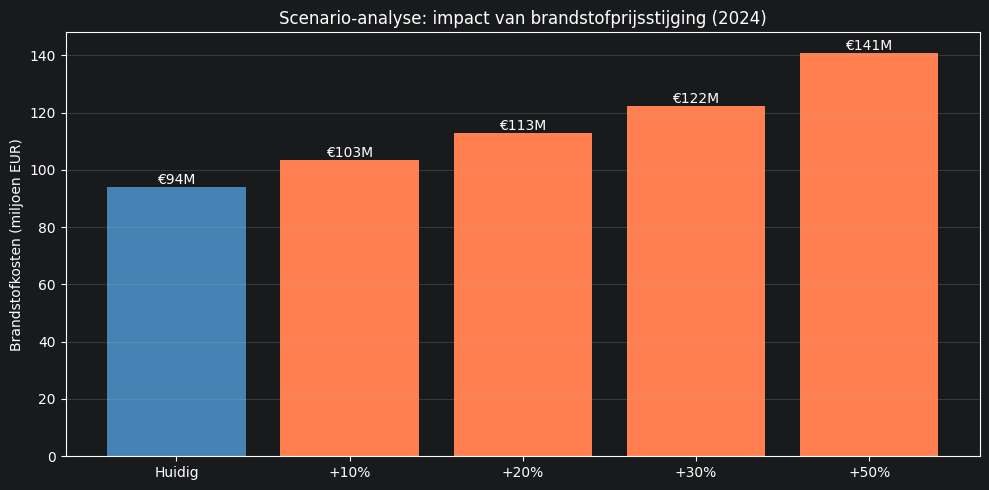

In [68]:
# Scenario-analyse grafiek
fig, ax = plt.subplots(figsize=(10, 5))

labels = ['Huidig'] + [f'+{s}%' for s in scenarios]
kosten = [kosten_2024] + [kosten_2024 * (1 + s/100) for s in scenarios]
kleuren = ['steelblue'] + ['coral'] * len(scenarios)

ax.bar(labels, [k / 1_000_000 for k in kosten], color=kleuren)
ax.set_ylabel('Brandstofkosten (miljoen EUR)')
ax.set_title('Scenario-analyse: impact van brandstofprijsstijging (2024)')
ax.grid(axis='y', alpha=0.3)

# Bedragen boven de balken
for i, k in enumerate(kosten):
    ax.text(i, k / 1_000_000 + 1, f'€{k/1_000_000:.0f}M', ha='center', fontsize=10)

plt.tight_layout()
plt.show()

Deze grafiek laat zien wat de financiële impact zou zijn als de brandstofprijs stijgt ten opzichte van het niveau van 2024. Bij een prijsstijging van 10% komen er ruim €9 miljoen aan extra kosten bij. Bij 30% loopt dit op tot €28 miljoen, en bij 50% tot bijna €47 miljoen. Deze scenario's zijn niet hypothetisch: in februari 2026 leidde de sluiting van de Straat van Hormuz tot een verdubbeling van de brandstofprijzen. De analyse onderstreept de noodzaak van een strategie om het prijsrisico te beheersen, zoals hedging of langetermijncontracten met brandstofleveranciers.

## 5. Kosten per vliegtuigtype

In [69]:
# Brandstofkosten per vliegtuigtype
per_type = flights.groupby('vliegtuigtype').agg(
    gem_brandstof_kg=('brandstof_kg', 'mean'),
    gem_kosten=('brandstofkost_eur', 'mean'),
    aantal_vluchten=('vlucht_id', 'count')
).sort_values('gem_kosten', ascending=False)

print("=== Gemiddelde brandstofkosten per vlucht, per vliegtuigtype ===")
for typ, rij in per_type.iterrows():
    print(f"{typ:30s}  €{rij['gem_kosten']:>10,.0f}  ({rij['aantal_vluchten']:.0f} vluchten)")

=== Gemiddelde brandstofkosten per vlucht, per vliegtuigtype ===
Airbus A330-300                 €    44,600  (742 vluchten)
Boeing 777-200LR                €    42,666  (652 vluchten)
Boeing 777-300ER                €    38,922  (723 vluchten)
Boeing 787-8                    €    31,147  (744 vluchten)
Boeing 787-9                    €    28,172  (789 vluchten)
Airbus A319                     €     7,196  (2493 vluchten)
Airbus A320                     €     7,011  (2479 vluchten)
Airbus A321                     €     6,044  (2479 vluchten)
Boeing 737 MAX 8                €     3,277  (2462 vluchten)
Airbus A220-300                 €     3,044  (2497 vluchten)


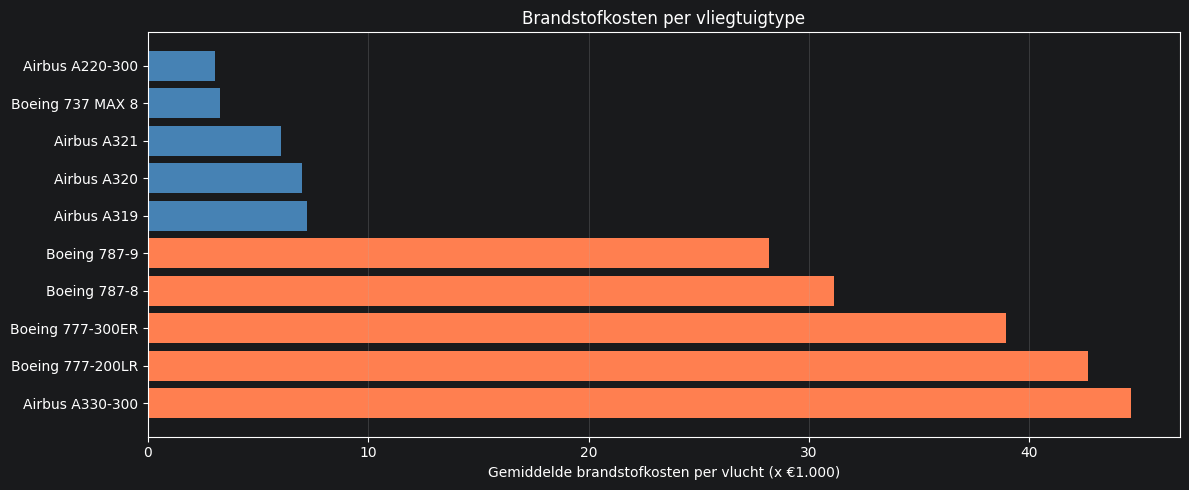

In [70]:
# Grafiek: brandstofkosten per vliegtuigtype
fig, ax = plt.subplots(figsize=(12, 5))

kleuren = ['coral' if k > 20000 else 'steelblue' for k in per_type['gem_kosten']]
ax.barh(per_type.index, per_type['gem_kosten'] / 1000, color=kleuren)
ax.set_xlabel('Gemiddelde brandstofkosten per vlucht (x €1.000)')
ax.set_title('Brandstofkosten per vliegtuigtype')
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

Er is een duidelijk verschil in brandstofkosten tussen de vliegtuigtypes in de vloot van Crunchr Airlines. De langeafstandstoestellen (Airbus A330, Boeing 777 en 787) kosten gemiddeld €28.000 tot €44.600 per vlucht aan brandstof, terwijl de korte en middenafstandstoestellen (A319, A320, A321, 737 MAX) tussen de €3.000 en €8.000 per vlucht kosten. Dit betekent dat prijsstijgingen het hardst aankomen bij de langeafstandsvluchten. Een stijging van 30% op een A330 vlucht kost €13.000 extra, terwijl diezelfde stijging op een 737 MAX slechts €1.000 extra kost. Bij het ontwikkelen van een hedgingstrategie verdienen de langeafstandsroutes daarom prioriteit.

## 6. Kosten per route

In [71]:
# Brandstofkosten per route
per_route = flights.groupby(['van', 'naar']).agg(
    gem_kosten=('brandstofkost_eur', 'mean'),
    totaal_kosten=('brandstofkost_eur', 'sum'),
    aantal_vluchten=('vlucht_id', 'count')
).sort_values('totaal_kosten', ascending=False)

print("=== Top 10 routes op totale brandstofkosten ===")
for (van, naar), rij in per_route.head(10).iterrows():
    print(f"{van} - {naar:15s}  Totaal: €{rij['totaal_kosten']:>12,.0f}  (gem: €{rij['gem_kosten']:>8,.0f}/vlucht)")

=== Top 10 routes op totale brandstofkosten ===
Amsterdam - New York         Totaal: €  51,752,946  (gem: €  35,447/vlucht)
Amsterdam - Dubai            Totaal: €  44,168,033  (gem: €  30,252/vlucht)
Amsterdam - Tokyo            Totaal: €  38,532,357  (gem: €  52,784/vlucht)
Amsterdam - Berlijn          Totaal: €  23,453,210  (gem: €   6,426/vlucht)
Amsterdam - Parijs           Totaal: €  21,961,166  (gem: €   5,014/vlucht)
Amsterdam - Londen           Totaal: €  20,557,690  (gem: €   4,694/vlucht)


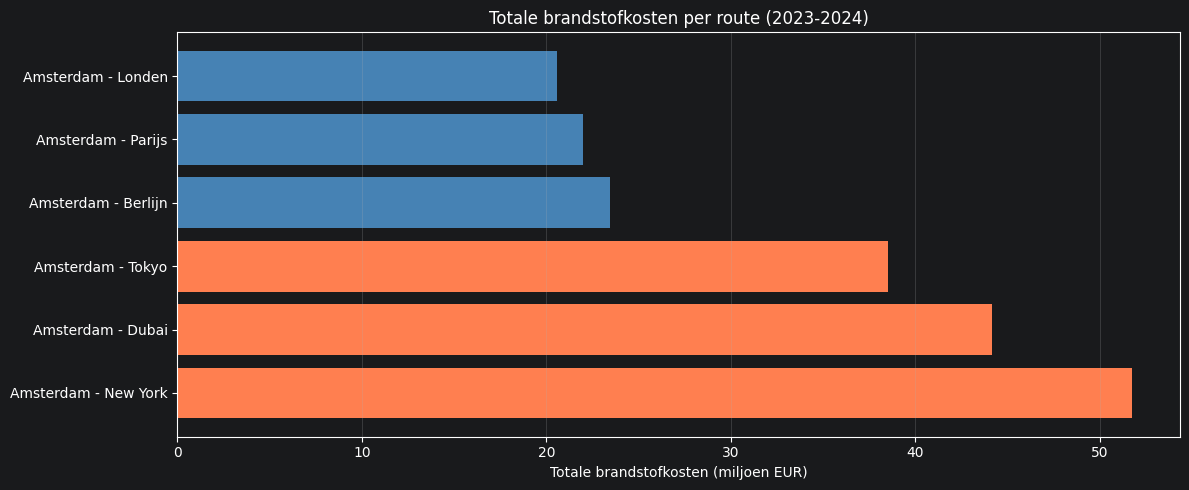

In [72]:
# Grafiek: totale brandstofkosten per route
fig, ax = plt.subplots(figsize=(12, 5))

ax.barh(
    [f"{v} - {n}" for (v, n) in per_route.index],
    per_route['totaal_kosten'] / 1_000_000,
    color=['coral' if k > 30_000_000 else 'steelblue' for k in per_route['totaal_kosten']]
)
ax.set_xlabel('Totale brandstofkosten (miljoen EUR)')
ax.set_title('Totale brandstofkosten per route (2023-2024)')
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

Amsterdam naar New York is de duurste route in totale brandstofkosten (€51,7 miljoen over twee jaar), gevolgd door Dubai (€44,2 miljoen) en Tokyo (€38,5 miljoen). Samen zijn deze drie langeafstandsroutes goed voor circa €134 miljoen, dat is tweederde van alle brandstofkosten. Per vlucht is Tokyo het duurst (€52.784), maar door het lagere aantal vluchten is het totaal lager dan New York. De Europese routes (Berlijn, Parijs, Londen) kosten per vlucht veel minder, maar vliegen veel frequenter. Voor risicobeheer is het verstandig om de aandacht eerst te richten op de drie grote langeafstandsroutes, omdat daar de grootste financiële blootstelling zit.

## 7. Volatiliteit (Coefficient of Variation)

In [73]:
# Volatiliteit berekenen (Coefficient of Variation)
maand_prijs_df = flights.groupby('maand')['brandstofprijs_eur_per_kg'].mean()

gemiddelde = maand_prijs_df.mean()
std = maand_prijs_df.std()
cv = (std / gemiddelde) * 100

print("=== Volatiliteit brandstofprijs ===")
print(f"Gemiddelde maandprijs:    €{gemiddelde:.4f}")
print(f"Standaarddeviatie:        €{std:.4f}")
print(f"Coefficient of Variation: {cv:.2f}%")
print()
print("Hoe hoger de CV, hoe onvoorspelbaarder de prijs.")
print("Ter vergelijking: elektriciteit heeft vaak een CV van 5-15%,")
print("ruwe olie 20-40%.")

=== Volatiliteit brandstofprijs ===
Gemiddelde maandprijs:    €0.8817
Standaarddeviatie:        €0.0756
Coefficient of Variation: 8.57%

Hoe hoger de CV, hoe onvoorspelbaarder de prijs.
Ter vergelijking: elektriciteit heeft vaak een CV van 5-15%,
ruwe olie 20-40%.


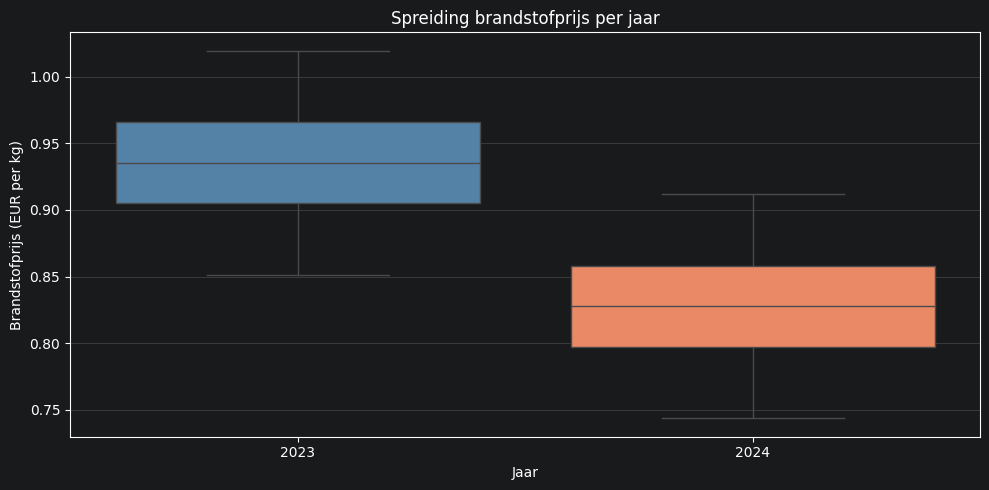

In [74]:
# Grafiek: maandelijkse prijsspreiding (boxplot per jaar)
flights['jaar_str'] = flights['jaar'].astype(str)

fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=flights, x='jaar_str', y='brandstofprijs_eur_per_kg', hue='jaar_str', palette=['steelblue', 'coral'], legend=False, ax=ax)
ax.set_xlabel('Jaar')
ax.set_ylabel('Brandstofprijs (EUR per kg)')
ax.set_title('Spreiding brandstofprijs per jaar')
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

De boxplot vergelijkt de spreiding van brandstofprijzen tussen 2023 en 2024. In 2023 lagen de prijzen hoger en was de spreiding breder, wat wijst op meer volatiliteit. In 2024 daalden de prijzen en werd de spreiding iets smaller. De Coefficient of Variation over de gehele periode is 8,57%, wat relatief laag is vergeleken met ruwe olie (20 tot 40%). Dit komt doordat 2023 en 2024 een relatief stabiele periode vormden. Het is belangrijk om te benadrukken dat deze historische stabiliteit geen garantie biedt voor de toekomst. Geopolitieke gebeurtenissen kunnen de volatiliteit snel opdrijven, zoals de Straat van Hormuz crisis in 2026 heeft aangetoond.

## 8. Machine Learning: Brandstofprijs Voorspelling (ARIMA)

In deze sectie gebruiken we een ARIMA model om de brandstofprijs te voorspellen. ARIMA staat voor AutoRegressive Integrated Moving Average. Simpel gezegd: het model kijkt naar patronen in het verleden (trends, seizoensgebonden schommelingen) en gebruikt die om de toekomst te voorspellen.

In [75]:
# statsmodels bevat het ARIMA model voor tijdreeksvoorspelling
!pip install statsmodels

In [76]:
# We maken een tijdreeks van de gemiddelde brandstofprijs per maand
# groupby('maand') groepeert alle vluchten per maand
# .mean() berekent het gemiddelde van elke groep
maand_reeks = flights.groupby('maand')['brandstofprijs_eur_per_kg'].mean()

# We zetten de index om naar een datum-formaat dat ARIMA begrijpt
# .to_timestamp() maakt van "2023-01" een echte datum (1 januari 2023)
maand_reeks.index = maand_reeks.index.to_timestamp()

# Laten we bekijken wat we hebben
print(f"Aantal maanden: {len(maand_reeks)}")
print()
print(maand_reeks)

Aantal maanden: 24

maand
2023-01-01    1.004845
2023-02-01    1.017204
2023-03-01    0.989994
2023-04-01    0.939893
2023-05-01    0.908268
2023-06-01    0.917750
2023-07-01    0.949894
2023-08-01    0.963023
2023-09-01    0.934457
2023-10-01    0.884261
2023-11-01    0.853957
2023-12-01    0.865206
2024-01-01    0.897794
2024-02-01    0.909317
2024-03-01    0.880258
2024-04-01    0.830063
2024-05-01    0.800255
2024-06-01    0.811630
2024-07-01    0.843816
2024-08-01    0.855084
2024-09-01    0.824660
2024-10-01    0.774490
2024-11-01    0.746037
2024-12-01    0.758563
Freq: MS, Name: brandstofprijs_eur_per_kg, dtype: float64


In [77]:
# We importeren het ARIMA model uit statsmodels
from statsmodels.tsa.arima.model import ARIMA

# We maken het model aan met onze tijdreeks
# order=(1,1,1) zijn de drie instellingen van ARIMA:
#   1e getal (p=1): het model kijkt 1 maand terug voor patronen
#   2e getal (d=1): het model corrigeert voor de trend (stijgend/dalend)
#   3e getal (q=1): het model houdt rekening met 1 eerdere voorspelfout
model = ARIMA(maand_reeks, order=(1,1,1))

# .fit() traint het model op de data
# Het model leert nu de patronen in de 24 maanden
resultaat = model.fit()

# Samenvatting van het model
print(resultaat.summary())

                                   SARIMAX Results                                   
Dep. Variable:     brandstofprijs_eur_per_kg   No. Observations:                   24
Model:                        ARIMA(1, 1, 1)   Log Likelihood                  61.531
Date:                       Thu, 29 Oct 2026   AIC                           -117.063
Time:                               15:02:33   BIC                           -113.656
Sample:                           01-01-2023   HQIC                          -116.206
                                - 12-01-2024                                         
Covariance Type:                         opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.4901      0.284      1.724      0.085      -0.067       1.047
ma.L1          0.9957     11.090      0.090      0.928     -20.740      22.

In [78]:
# Voorspel 6 maanden vooruit (januari t/m juni 2025)
voorspelling = resultaat.forecast(steps=6)

# Toon de voorspelde prijzen
print("=== Voorspelde brandstofprijs per maand ===")
for datum, prijs in voorspelling.items():
    print(f"{datum.strftime('%B %Y'):15s}  €{prijs:.4f} per kg")

=== Voorspelde brandstofprijs per maand ===
January 2025     €0.7822 per kg
February 2025    €0.7937 per kg
March 2025       €0.7994 per kg
April 2025       €0.8022 per kg
May 2025         €0.8035 per kg
June 2025        €0.8042 per kg


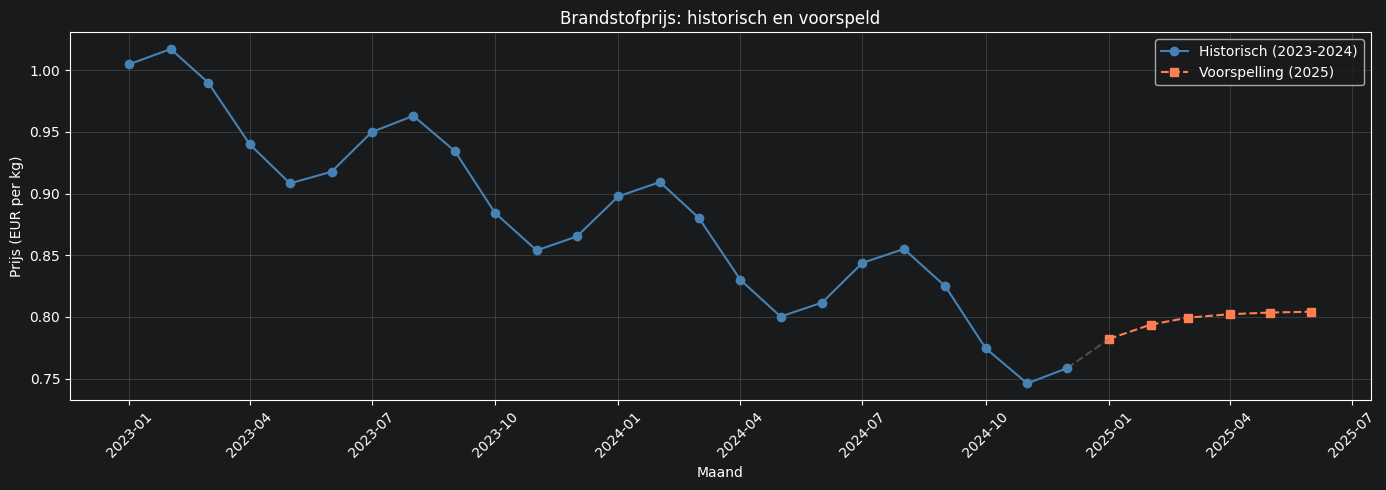

In [79]:
# Grafiek: historische data + voorspelling
fig, ax = plt.subplots(figsize=(14, 5))

# Historische data (blauwe lijn)
ax.plot(maand_reeks.index, maand_reeks.values, marker='o', color='steelblue', label='Historisch (2023-2024)')

# Voorspelling (rode stippellijn)
ax.plot(voorspelling.index, voorspelling.values, marker='s', color='coral', linestyle='--', label='Voorspelling (2025)')

# Stippellijn tussen laatste echte punt en eerste voorspelling
ax.plot([maand_reeks.index[-1], voorspelling.index[0]],
        [maand_reeks.values[-1], voorspelling.values[0]],
        color='gray', linestyle='--', alpha=0.5)

ax.set_title('Brandstofprijs: historisch en voorspeld')
ax.set_ylabel('Prijs (EUR per kg)')
ax.set_xlabel('Maand')
ax.legend()
ax.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Het ARIMA(1,1,1) model is getraind op 24 maanden aan historische brandstofprijzen (januari 2023 tot en met december 2024). Op basis van de patronen in deze data voorspelt het model een stabilisatie van de brandstofprijs rond €0.80 per kilogram in de eerste helft van 2025. Dit ligt iets boven het dieptepunt van eind 2024 (€0.75), maar ruim onder de piek van begin 2023 (€1.02).

Het is belangrijk om te benadrukken dat dit model alleen leert van historische patronen. Het kan geen onverwachte externe gebeurtenissen voorspellen, zoals geopolitieke conflicten of plotselinge aanbodverstoringen. De werkelijke brandstofprijs in 2025 en 2026 is fors hoger gebleken door de sluiting van de Straat van Hormuz in februari 2026. Dit benadrukt juist de noodzaak van een hedgingstrategie: zelfs een betrouwbaar model kan niet alle risico's voorzien, waardoor financiële bescherming tegen prijsschokken essentieel blijft.

## 9. (Model 1) Regressie Evaluatie - ARIMA Model
### Inleiding
Naast het classificatiemodel evalueren we ook ons ARIMA regressiemodel. Bij regressie voorspel je geen categorie (duur/goedkoop), maar een exact getal: de brandstofprijs per kg. Daarom gebruiken we andere evaluatiematen.

### Aanpak
We splitsen de maandelijkse brandstofprijzen in een trainingsperiode (januari 2023 t/m juli 2024, 19 maanden) en een testperiode (augustus t/m december 2024, 5 maanden). Het model leert patronen uit de trainingsdata en voorspelt vervolgens de testperiode. Die voorspelling vergelijken we met de werkelijke waarden.

In [80]:
maandelijks = flights.groupby(flights['datum'].dt.to_period('M'))['brandstofprijs_eur_per_kg'].mean()
maandelijks.index = maandelijks.index.to_timestamp()
print(f"Aantal maanden: {len(maandelijks)}")
print(maandelijks.head())

Aantal maanden: 24
datum
2023-01-01    1.004845
2023-02-01    1.017204
2023-03-01    0.989994
2023-04-01    0.939893
2023-05-01    0.908268
Freq: MS, Name: brandstofprijs_eur_per_kg, dtype: float64


In [81]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# We splitsen de data in train en test
split = int(len(maandelijks) * 0.8)
train = maandelijks[:split]
test = maandelijks[split:]

print(f"Trainingsperiode: {train.index[0].strftime('%Y-%m')} t/m {train.index[-1].strftime('%Y-%m')}")
print(f"Testperiode: {test.index[0].strftime('%Y-%m')} t/m {test.index[-1].strftime('%Y-%m')}")
print(f"Train: {len(train)} maanden, Test: {len(test)} maanden")

Trainingsperiode: 2023-01 t/m 2024-07
Testperiode: 2024-08 t/m 2024-12
Train: 19 maanden, Test: 5 maanden


In [82]:
from statsmodels.tsa.arima.model import ARIMA

# Train ARIMA op alleen de trainingsdata
model_arima = ARIMA(train, order=(1,1,1))
model_fit = model_arima.fit()

# Voorspel de 5 testmaanden
voorspelling = model_fit.forecast(steps=len(test))

print("Werkelijke waarden:")
for datum, prijs in test.items():
    print(f"  {datum.strftime('%Y-%m')}: €{prijs:.4f}")

print("\nVoorspelde waarden:")
for datum, prijs in zip(test.index, voorspelling):
    print(f"  {datum.strftime('%Y-%m')}: €{prijs:.4f}")

Werkelijke waarden:
  2024-08: €0.8551
  2024-09: €0.8247
  2024-10: €0.7745
  2024-11: €0.7460
  2024-12: €0.7586

Voorspelde waarden:
  2024-08: €0.8686
  2024-09: €0.8811
  2024-10: €0.8874
  2024-11: €0.8906
  2024-12: €0.8922


In [83]:
mae = mean_absolute_error(test, voorspelling)
mse = mean_squared_error(test, voorspelling)
rmse = np.sqrt(mse)
r2 = r2_score(test, voorspelling)

print("=== Regressie Evaluatie ARIMA ===")
print(f"MAE  (Mean Absolute Error):  €{mae:.4f}")
print(f"MSE  (Mean Squared Error):   €{mse:.6f}")
print(f"RMSE (Root Mean Sq. Error):  €{rmse:.4f}")
print(f"R²   (R-squared):            {r2:.4f}")

=== Regressie Evaluatie ARIMA ===
MAE  (Mean Absolute Error):  €0.0922
MSE  (Mean Squared Error):   €0.010974
RMSE (Root Mean Sq. Error):  €0.1048
R²   (R-squared):            -5.3925


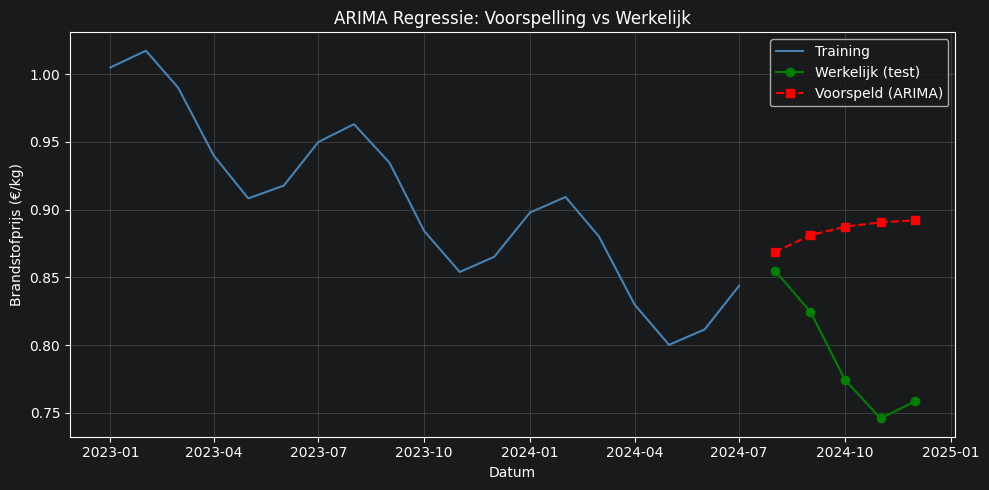

In [84]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(train.index, train, color='steelblue', label='Training')
ax.plot(test.index, test, color='green', marker='o', label='Werkelijk (test)')
ax.plot(test.index, voorspelling, color='red', marker='s', linestyle='--', label='Voorspeld (ARIMA)')

ax.set_title('ARIMA Regressie: Voorspelling vs Werkelijk')
ax.set_xlabel('Datum')
ax.set_ylabel('Brandstofprijs (€/kg)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Evaluatiematen
- **MAE (€0,0922)**: het model zit gemiddeld 9 cent per kg ernaast, een afwijking van ongeveer 11%
- **RMSE (€0,1048)**: iets hoger dan de MAE, wat betekent dat sommige maanden verder afwijken dan andere
- **R² (-5,39)**: negatief, het model voorspelt slechter dan simpelweg het gemiddelde gebruiken

### Interpretatie
Het ARIMA model presteert slecht op de testperiode. De reden is zichtbaar in de grafiek: de werkelijke prijzen dalen sterk vanaf augustus 2024, maar het model voorspelt een vlakke lijn. ARIMA leert alleen van historische patronen en kan geen externe factoren meenemen zoals dalende olieprijzen. Met slechts 19 maanden trainingsdata is er te weinig informatie om een trendbreuk te voorspellen.

Dit is een belangrijke beperking van univariate tijdreeksmodellen. Een multivariate aanpak, zoals SARIMAX met olieprijzen als externe variabele, kan deze beperking deels ondervangen.

### Conclusie model 1: ARIMA op maandgemiddelden

**Werking:** ARIMA(1,1,1) leert uit de 24 maandgemiddelden alleen van het eigen verleden. Het model traint op 80 procent van de reeks en voorspelt de laatste vijf maanden.

**Resultaat:** MAE €0,0922, RMSE €0,1048 en R² -5,39. Het model voorspelt een vlakke lijn, terwijl de werkelijke prijs daalt.

**Conclusie:** niet bruikbaar. Met 24 datapunten kan het model de daling niet volgen. Het is wel een nuttige vergelijking, omdat het laat zien waarom we zijn overgestapt op dagdata.

**Plus:** eenvoudig en makkelijk uit te leggen.
**Min:** te weinig datapunten, geen reactie op trendbreuken, en het dagverloop gaat verloren.

## 10. (Model 2) Classificatiemodel: Brandstofprijs voorspellen

### Inleiding
In dit onderdeel passen we een machine learning classificatiemodel toe op de vluchtdata van Crunchr Airlines. Het model voorspelt per vlucht of de brandstofprijs **duur** of **goedkoop** is, op basis van vier kenmerken:
1. Brandstofverbruik in kg
2. Vliegduur in block uren
3. Maandnummer
4. Jaar

Dit is relevant voor ons onderzoek naar brandstofprijsvolatiliteit omdat het laat zien of prijsniveaus voorspelbaar zijn vanuit operationele vluchtgegevens. Als het model goed presteert, betekent dit dat er duidelijke patronen zitten in wanneer brandstof duur of goedkoop is. Crunchr Airlines kan die kennis gebruiken om beter te budgetteren en op het juiste moment brandstof in te kopen.

Daarnaast gebruiken we dit model om te oefenen met model evaluatie: hoe beoordeel je of een model goed werkt? Welke fouten maakt het, en welke fouten zijn het gevaarlijkst voor de luchtvaartmaatschappij? Een model dat een dure vlucht als goedkoop bestempelt is gevaarlijker dan andersom, omdat dit leidt tot te lage budgetreserveringen.

In [85]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

# Stap 1: Label aanmaken
# We delen vluchten in twee groepen: "duur" en "goedkoop"
# De grens is de mediaan van de brandstofprijs
mediaan = flights['brandstofprijs_eur_per_kg'].median()
flights['label'] = (flights['brandstofprijs_eur_per_kg'] >= mediaan).astype(int)

print(f"Mediaan brandstofprijs: €{mediaan:.4f}/kg")
print(f"Goedkoop (0): {(flights['label'] == 0).sum()} vluchten")
print(f"Duur (1):     {(flights['label'] == 1).sum()} vluchten")

Mediaan brandstofprijs: €0.8815/kg
Goedkoop (0): 8030 vluchten
Duur (1):     8030 vluchten


In [86]:
# Stap 2: Features klaarmaken
# We gebruiken kolommen die de brandstofprijs kunnen beïnvloeden
# maar NIET de prijs zelf (want die willen we voorspellen)

flights['maand_nr'] = flights['datum'].dt.month
flights['jaar'] = flights['datum'].dt.year

# Features: brandstofverbruik, block uren, maand en jaar
features = ['brandstof_kg', 'block_uren', 'maand_nr', 'jaar']

X = flights[features]
y = flights['label']

print("Features die het model gebruikt:")
for f in features:
    print(f"  - {f}")
print()
print(X.head())

Features die het model gebruikt:
  - brandstof_kg
  - block_uren
  - maand_nr
  - jaar

   brandstof_kg  block_uren  maand_nr  jaar
0        3157.0        1.29         1  2023
1        3067.4        1.37         1  2023
2        3055.2        1.36         1  2023
3        7182.7        1.33         1  2023
4        5953.3        1.31         1  2023


In [87]:
# Stap 3: Data splitsen in train en test
# 80% om van te leren, 20% om te testen
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Trainingsset: {len(X_train)} vluchten")
print(f"Testset:      {len(X_test)} vluchten")

Trainingsset: 12848 vluchten
Testset:      3212 vluchten


In [88]:
# Stap 4: Model trainen en voorspellen
# RandomForest is een model dat meerdere beslisbomen combineert
# Elke boom kijkt naar de features en stemt mee: duur of goedkoop?
model_rf = RandomForestClassifier(n_estimators=100, random_state=42)

# Het model leert van de trainingsdata
model_rf.fit(X_train, y_train)

# Voorspellen op de testdata (data die het model nog nooit heeft gezien)
y_pred = model_rf.predict(X_test)

# Hoe goed deed het model het?
acc = accuracy_score(y_test, y_pred)
print(f"Accuracy: {acc:.2%}")

Accuracy: 95.77%


In [89]:
# Stap 5: Confusion matrix en classification report
cm = confusion_matrix(y_test, y_pred)
rapport = classification_report(y_test, y_pred, target_names=['Goedkoop', 'Duur'])

print("=== Confusion Matrix ===")
print(f"                 Voorspeld Goedkoop  Voorspeld Duur")
print(f"Echt Goedkoop         {cm[0][0]:>10}        {cm[0][1]:>10}")
print(f"Echt Duur              {cm[1][0]:>10}        {cm[1][1]:>10}")
print()
print("=== Classification Report ===")
print(rapport)

=== Confusion Matrix ===
                 Voorspeld Goedkoop  Voorspeld Duur
Echt Goedkoop               1506                77
Echt Duur                      59              1570

=== Classification Report ===
              precision    recall  f1-score   support

    Goedkoop       0.96      0.95      0.96      1583
        Duur       0.95      0.96      0.96      1629

    accuracy                           0.96      3212
   macro avg       0.96      0.96      0.96      3212
weighted avg       0.96      0.96      0.96      3212



## Model Evaluatie - Classificatiemodel

We bouwen een classificatiemodel om te oefenen met model evaluatie. Het doel: voorspellen of een vlucht een **dure** of **goedkope** brandstofprijs heeft.

### Aanpak
- **Label**: op basis van de mediaan brandstofprijs (€0.8815/kg) verdelen we vluchten in twee klassen: goedkoop (0) en duur (1)
- **Features**: brandstof_kg, block_uren, maand_nr, jaar
- **Model**: RandomForest Classifier (100 bomen)
- **Split**: 80% training (12.848 vluchten), 20% test (3.212 vluchten)



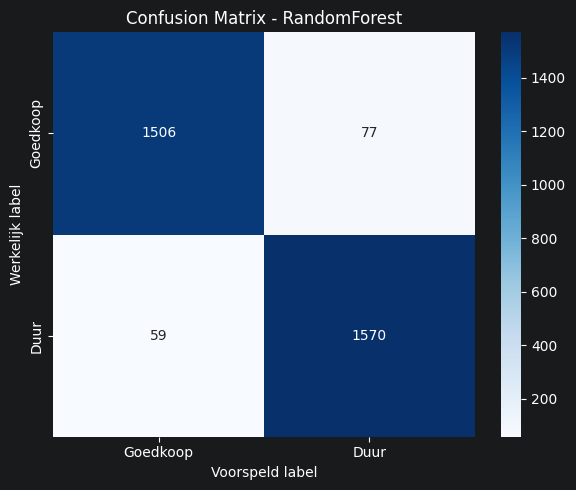

In [90]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Goedkoop', 'Duur'],
            yticklabels=['Goedkoop', 'Duur'], ax=ax)
ax.set_xlabel('Voorspeld label')
ax.set_ylabel('Werkelijk label')
ax.set_title('Confusion Matrix - RandomForest')
plt.tight_layout()
plt.show()

### Resultaten
- **Accuracy**: 95,77%, het model voorspelt dus 96 van de 100 vluchten correct
- **Precision**: 0,95 (goedkoop) en 0,96 (duur), van alle vluchten die het model als "duur" bestempelt, is 96% ook echt duur
- **Recall**: 0,95 (goedkoop) en 0,96 (duur), van alle werkelijk dure vluchten vindt het model er 96%
- **F1-score**: 0,95 en 0,96, de balans tussen precision en recall

### Confusion Matrix
De heatmap hieronder toont de vier mogelijke uitkomsten:
- **True Negative (1506)**: correct voorspeld als goedkoop
- **False Positive (77)**: voorspeld als duur, maar was goedkoop
- **False Negative (59)**: voorspeld als goedkoop, maar was duur. Dit is de gevaarlijkste fout voor Crunchr Airlines, want hierdoor wordt er te weinig budget gereserveerd voor brandstof
- **True Positive (1570)**: correct voorspeld als duur

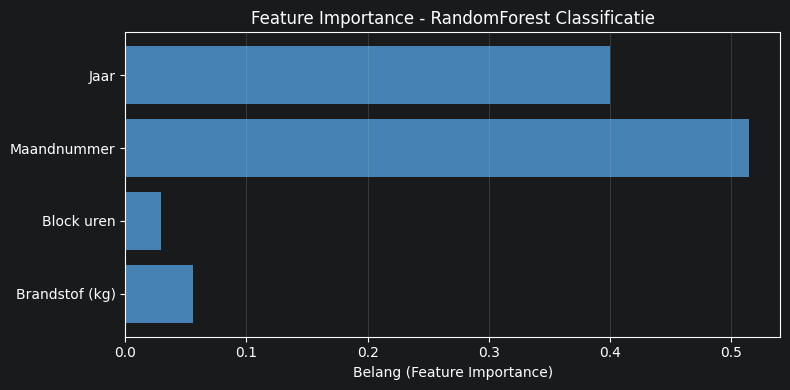

Brandstof (kg): 0.0560 (5.6%)
Block uren: 0.0292 (2.9%)
Maandnummer: 0.5148 (51.5%)
Jaar: 0.4001 (40.0%)


In [91]:
importances = model_rf.feature_importances_
feature_namen = ['Brandstof (kg)', 'Block uren', 'Maandnummer', 'Jaar']

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(feature_namen, importances, color='steelblue')
ax.set_xlabel('Belang (Feature Importance)')
ax.set_title('Feature Importance - RandomForest Classificatie')
ax.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

for naam, belang in zip(feature_namen, importances):
    print(f"{naam}: {belang:.4f} ({belang*100:.1f}%)")

### Feature Importance
Feature importance laat zien welke kenmerken het meest bijdragen aan de voorspelling van het model. Het RandomForest model berekent dit automatisch: bij het bouwen van de 100 beslisbomen houdt het bij welke kenmerken het vaakst en het meest effectief worden gebruikt om de data te splitsen.

Een hoge score betekent dat het model sterk leunt op dat kenmerk om te bepalen of een vlucht duur of goedkoop is. Een lage score betekent dat het kenmerk weinig toevoegt aan de voorspelling.

Dit is nuttig voor Crunchr Airlines omdat het laat zien welke factoren het meest samenhangen met hoge brandstofprijzen. Als bijvoorbeeld het jaar de belangrijkste factor is, wijst dat op een sterke prijstrend over tijd. Als het maandnummer belangrijk is, wijst dat op seizoenspatronen.

# 11 (Model 2.1) Nieuw Classificatiemodel met vliegtuig type als extra


In [92]:
from sklearn.preprocessing import LabelEncoder

# Vliegtuigtype omzetten van tekst naar getallen
le = LabelEncoder()
flights['vliegtuigtype_code'] = le.fit_transform(flights['vliegtuigtype'])

# Laat de vertaling zien
print("Vliegtuigtype codering:")
for tekst, code in zip(le.classes_, range(len(le.classes_))):
    print(f"  {tekst} = {code}")

Vliegtuigtype codering:
  Airbus A220-300 = 0
  Airbus A319 = 1
  Airbus A320 = 2
  Airbus A321 = 3
  Airbus A330-300 = 4
  Boeing 737 MAX 8 = 5
  Boeing 777-200LR = 6
  Boeing 777-300ER = 7
  Boeing 787-8 = 8
  Boeing 787-9 = 9


In [93]:
# Features nu met vliegtuigtype
features_v2 = ['brandstof_kg', 'block_uren', 'maand_nr', 'jaar', 'vliegtuigtype_code']
X2 = flights[features_v2]
y2 = flights['label']

# Train/test split
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, test_size=0.2, random_state=42)

# Model trainen
model_rf2 = RandomForestClassifier(n_estimators=100, random_state=42)
model_rf2.fit(X2_train, y2_train)
y2_pred = model_rf2.predict(X2_test)

# Vergelijking
acc2 = accuracy_score(y2_test, y2_pred)
print(f"Accuracy ZONDER vliegtuigtype: {acc:.4f} ({acc*100:.2f}%)")
print(f"Accuracy MET vliegtuigtype:    {acc2:.4f} ({acc2*100:.2f}%)")
print(f"\nClassification Report:")
print(classification_report(y2_test, y2_pred, target_names=['Goedkoop', 'Duur']))

Accuracy ZONDER vliegtuigtype: 0.9577 (95.77%)
Accuracy MET vliegtuigtype:    0.9577 (95.77%)

Classification Report:
              precision    recall  f1-score   support

    Goedkoop       0.96      0.95      0.96      1583
        Duur       0.95      0.96      0.96      1629

    accuracy                           0.96      3212
   macro avg       0.96      0.96      0.96      3212
weighted avg       0.96      0.96      0.96      3212



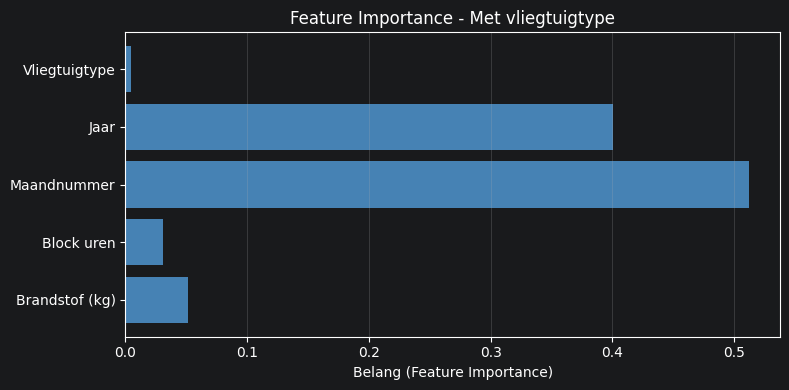

Brandstof (kg): 0.0518 (5.2%)
Block uren: 0.0309 (3.1%)
Maandnummer: 0.5120 (51.2%)
Jaar: 0.4004 (40.0%)
Vliegtuigtype: 0.0049 (0.5%)


In [94]:
importances2 = model_rf2.feature_importances_
feature_namen2 = ['Brandstof (kg)', 'Block uren', 'Maandnummer', 'Jaar', 'Vliegtuigtype']

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(feature_namen2, importances2, color='steelblue')
ax.set_xlabel('Belang (Feature Importance)')
ax.set_title('Feature Importance - Met vliegtuigtype')
ax.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

for naam, belang in zip(feature_namen2, importances2):
    print(f"{naam}: {belang:.4f} ({belang*100:.1f}%)")

### Conclusie model 2: random forest classificatie op vluchten

**Werking:** per vlucht wordt de brandstofprijs als duur (boven de mediaan) of goedkoop gelabeld. Het model gebruikt brandstofverbruik, blokuren, maandnummer en jaar. In model 2.1 is ook het vliegtuigtype toegevoegd. De data wordt willekeurig gesplitst in 80 procent training en 20 procent test.

**Resultaat:** accuracy 95,77 procent. Het jaar en de maand verklaren het grootste deel van de feature importance.

**Conclusie:** de score is te hoog om te geloven. Vluchten uit dezelfde maand zitten zowel in de training als in de test, en het jaar en de maand zijn precies de periode die het model moet voorspellen. Het model laat zien dat de prijs samenhangt met de tijd, maar het voorspelt niets vooraf. Daarom is het niet bruikbaar voor afdekking.

**Plus:** snel, eenvoudig, en de feature importance geeft een eerste beeld.
**Min:** lekkage door de willekeurige split, geen voorspelling vooraf, en een hoge accuracy die misleidt.

## 12. (Model 3) Nieuw classificatiemodel voor fuel hedging

### Waarom een nieuw model?
Het vorige classificatiemodel (cel 49 tot 62) heeft twee zwaktes voor dit doel:
1. De train/test-split is willekeurig. Vluchten uit dezelfde maand komen dan in zowel de training als de test terecht, waardoor het model te optimistisch lijkt.
2. Het model gebruikt het jaar en het maandnummer en voorspelt de prijs van dezelfde vlucht waarvan het verbruik bekend is. Daarmee voorspelt het niets vooraf.

Voor afdekking is de vraag anders: **kunnen we op basis van de situatie van deze maand voorspellen of de brandstofprijs volgende maand boven de drempel komt?** Daarom:
- voorspellen we per maand, voor de volgende maand (target = prijs in t+1);
- gebruiken we alleen informatie uit eerdere maanden (lag-features);
- splitsen we op tijd: training tot en met mei 2024, test juni t/m november 2024;
- leggen we de nadruk op **recall voor "duur"**: een gemiste dure maand is het gevaarlijkst, omdat er dan te weinig budget is gereserveerd.

Let op: de dataset heeft 24 maanden. Na het maken van de lag-features blijven er ongeveer 13 trainingsrijen en 6 testrijen over. De resultaten zijn daarom indicatief en geen bewijs.

In [95]:
# Maandtabel opbouwen op basis van de vluchtdata
maand_df = (
    flights.groupby('maand')
    .agg(
        prijs=('brandstofprijs_eur_per_kg', 'mean'),
        kg=('brandstof_kg', 'sum'),
        block_uren=('block_uren', 'mean'),
        vluchten=('vlucht_id', 'count'),
    )
    .sort_index()
)
maand_df.index = maand_df.index.to_timestamp()
maand_df['maand_nr'] = maand_df.index.month

# Kenmerken: alleen informatie uit eerdere maanden (geen lekkage)
for lag in [1, 2, 3]:
    maand_df[f'prijs_lag{lag}'] = maand_df['prijs'].shift(lag)
maand_df['prijs_gem3'] = maand_df['prijs'].shift(1).rolling(3).mean()
maand_df['prijs_verandering'] = maand_df['prijs'].shift(1).pct_change()
maand_df['kg_lag1'] = maand_df['kg'].shift(1)
maand_df['vluchten_lag1'] = maand_df['vluchten'].shift(1)
maand_df['block_uren_lag1'] = maand_df['block_uren'].shift(1)

# Target: is de prijs in de VOLGENDE maand duur?
maand_df['prijs_volgende'] = maand_df['prijs'].shift(-1)
maand_df['kg_volgende'] = maand_df['kg'].shift(-1)

# Drempel bepalen op de trainingsdata (tot en met mei 2024), zodat de test niet meekijkt
TRAIN_LAATSTE_DOEL = pd.Timestamp('2024-05-01')
drempel = maand_df.loc[maand_df.index <= TRAIN_LAATSTE_DOEL, 'prijs'].median()
maand_df['label'] = (maand_df['prijs_volgende'] >= drempel).astype(float)

print(f"Drempel (mediaan trainingsperiode): €{drempel:.4f}/kg")
print()
print(maand_df[['prijs', 'prijs_volgende', 'label']].round(4).to_string())

Drempel (mediaan trainingsperiode): €0.9093/kg

             prijs  prijs_volgende  label
maand                                    
2023-01-01  1.0048          1.0172    1.0
2023-02-01  1.0172          0.9900    1.0
2023-03-01  0.9900          0.9399    1.0
2023-04-01  0.9399          0.9083    0.0
2023-05-01  0.9083          0.9178    1.0
2023-06-01  0.9178          0.9499    1.0
2023-07-01  0.9499          0.9630    1.0
2023-08-01  0.9630          0.9345    1.0
2023-09-01  0.9345          0.8843    0.0
2023-10-01  0.8843          0.8540    0.0
2023-11-01  0.8540          0.8652    0.0
2023-12-01  0.8652          0.8978    0.0
2024-01-01  0.8978          0.9093    1.0
2024-02-01  0.9093          0.8803    0.0
2024-03-01  0.8803          0.8301    0.0
2024-04-01  0.8301          0.8003    0.0
2024-05-01  0.8003          0.8116    0.0
2024-06-01  0.8116          0.8438    0.0
2024-07-01  0.8438          0.8551    0.0
2024-08-01  0.8551          0.8247    0.0
2024-09-01  0.8247          

In [96]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Geen jaar-kolom: alleen prijs-historie, volume, vlootgebruik en seizoen (maandnummer)
features_fh = ['prijs_lag1', 'prijs_lag2', 'prijs_lag3', 'prijs_gem3', 'prijs_verandering',
               'kg_lag1', 'vluchten_lag1', 'block_uren_lag1', 'maand_nr']

model_df = maand_df.dropna(subset=features_fh + ['label', 'prijs_volgende', 'kg_volgende'])

# Tijdgebaseerde split: nooit random
train = model_df[model_df.index <= TRAIN_LAATSTE_DOEL]
test = model_df[model_df.index > TRAIN_LAATSTE_DOEL]

y_train = train['label'].astype(int)
y_test = test['label'].astype(int)

print(f"Train: {len(train)} maanden ({train.index[0]:%Y-%m} t/m {train.index[-1]:%Y-%m})")
print(f"Test:  {len(test)} maanden ({test.index[0]:%Y-%m} t/m {test.index[-1]:%Y-%m})")
print()

# Baseline: 'volgende maand is net zo duur als deze maand'
base_pred = (test['prijs'] >= drempel).astype(int).values

modellen = {
    'Baseline (persistentie)': None,
    'Logistische regressie': make_pipeline(
        StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=1000)),
    'RandomForest (max diepte 3)': RandomForestClassifier(
        n_estimators=200, max_depth=3, class_weight='balanced', random_state=42),
}

voorspellingen = {}
rijen = []
for naam, model in modellen.items():
    if model is None:
        pred = base_pred
    else:
        model.fit(train[features_fh], y_train)
        pred = model.predict(test[features_fh])
    voorspellingen[naam] = pred
    rijen.append({
        'model': naam,
        'accuracy': accuracy_score(y_test, pred),
        'precision_duur': precision_score(y_test, pred, zero_division=0),
        'recall_duur': recall_score(y_test, pred, zero_division=0),
        'f1_duur': f1_score(y_test, pred, zero_division=0),
    })

resultaten = pd.DataFrame(rijen).round(3)
print(resultaten.to_string(index=False))

Train: 14 maanden (2023-04 t/m 2024-05)
Test:  6 maanden (2024-06 t/m 2024-11)

                      model  accuracy  precision_duur  recall_duur  f1_duur
    Baseline (persistentie)       1.0             0.0          0.0      0.0
      Logistische regressie       1.0             0.0          0.0      0.0
RandomForest (max diepte 3)       1.0             0.0          0.0      0.0


In [97]:
# Een gemiste dure maand (echt duur, voorspeld goedkoop) is de gevaarlijkste fout.
# Als schatting van de blootstelling rekenen we de prijs boven de drempel maal het volume van die maand.
blootstelling = ((test['prijs_volgende'] - drempel).clip(lower=0) * test['kg_volgende']).values

for naam, pred in voorspellingen.items():
    gemist = (y_test.values == 1) & (pred == 0)
    print(f"{naam}:")
    print(f"  Gemiste dure maanden: {gemist.sum()} van {(y_test == 1).sum()}")
    print(f"  Blootstelling boven drempel in gemiste maanden: €{blootstelling[gemist].sum():,.0f}")
    print()

Baseline (persistentie):
  Gemiste dure maanden: 0 van 0
  Blootstelling boven drempel in gemiste maanden: €0

Logistische regressie:
  Gemiste dure maanden: 0 van 0
  Blootstelling boven drempel in gemiste maanden: €0

RandomForest (max diepte 3):
  Gemiste dure maanden: 0 van 0
  Blootstelling boven drempel in gemiste maanden: €0



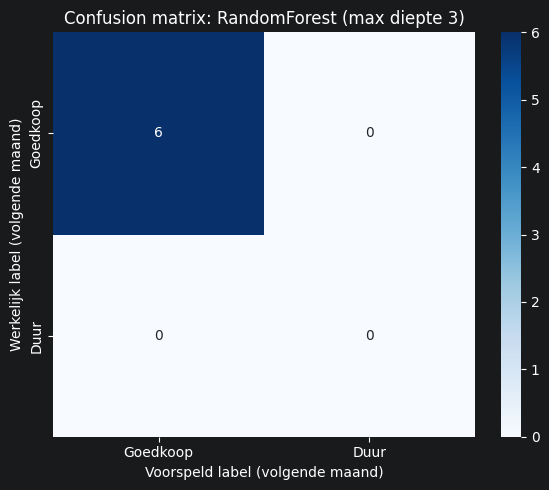

In [98]:
import seaborn as sns

gekozen = 'RandomForest (max diepte 3)'  # of 'Logistische regressie'
cm_fh = confusion_matrix(y_test, voorspellingen[gekozen], labels=[0, 1])

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_fh, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Goedkoop', 'Duur'], yticklabels=['Goedkoop', 'Duur'], ax=ax)
ax.set_xlabel('Voorspeld label (volgende maand)')
ax.set_ylabel('Werkelijk label (volgende maand)')
ax.set_title(f'Confusion matrix: {gekozen}')
plt.tight_layout()
plt.show()

### Hoe lees je de resultaten?
- **Recall voor "duur"** is de belangrijkste maat. Het zegt hoeveel van de werkelijk dure maanden het model vooraf signaleert.
- **Precision voor "duur"** zegt hoe vaak een signaal ook echt een dure maand blijkt. Een lage precision kost alleen extra afdekking, een lage recall kost geld.
- **Baseline**: een model is alleen waardevol als het de persistentie-baseline verslaat op recall zonder de precision te laten instorten.
- Met zes testmaanden is één fout al ongeveer 17 procentpunt. Gebruik de resultaten als richting, niet als bewijs.

### Vervolgstappen
1. Testperiode uitbreiden door de data van 2025 en 2026 toe te voegen (zodra die beschikbaar is).
2. De drempel koppelen aan het afdekkingsbeleid van het bestuur (bijvoorbeeld het budgetniveau) in plaats van de mediaan.
3. De blootstelling per routegroep (lange afstand tegenover kort en middellang) meenemen, omdat de risico's daar verschillen.
4. De reconciliatie van vloot en brandstofvolume afronden voordat de blootstelling in euro's wordt gerapporteerd.

### Conclusie model 3: classificatie voor hedging op maandniveau

**Werking:** per maand wordt voorspeld of de prijs in de volgende maand boven de drempel komt. Het model gebruikt vertraagde prijzen en een tijdgebaseerde split, zodat het niet meekijkt naar de toekomst.

**Resultaat met het drempellabel:** de drempel is de mediaan van de training. Omdat de prijs in 2024 daalde, is er in de testperiode geen enkele dure maand. Recall en precision zijn daardoor niet te berekenen.

**Vervolg:** hieronder staat een tweede beoordeling met een stijgingslabel (de prijs is volgende maand hoger dan deze maand). Dat label heeft beide klassen in de data. Over 12 maanden met een uitbreidend venster krijgt het logistische model een accuracy van 0,75, tegenover 0,50 voor het model dat altijd een stijging voorspelt. De recall voor stijgingen is 1,00 en de precision 0,67.

**Conclusie:** het model heeft een zwak signaal, maar het verschil met altijd afdekken is op 12 maanden niet significant. Niet bruikbaar als betrouwbaar afdekkingssignaal. Het is een open punt voor de vervolgstappen.

### Stijgingslabel: uitbreidend venster
Dit label vergelijkt de prijs van volgende maand met die van deze maand. Het venster groeit elke maand, zodat elk testpunt alleen eerdere data gebruikt.

In [99]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier

# Maandtabel met vertraagde kenmerken (alleen eerdere maanden)
maand_s = (
    flights.groupby('maand')
    .agg(prijs=('brandstofprijs_eur_per_kg', 'mean'),
         kg=('brandstof_kg', 'sum'),
         block_uren=('block_uren', 'mean'),
         vluchten=('vlucht_id', 'count'))
    .sort_index()
)
maand_s.index = maand_s.index.to_timestamp()
maand_s['maand_nr'] = maand_s.index.month
for lag in [1, 2, 3]:
    maand_s[f'prijs_lag{lag}'] = maand_s['prijs'].shift(lag)
maand_s['prijs_gem3'] = maand_s['prijs'].shift(1).rolling(3).mean()
maand_s['prijs_verandering'] = maand_s['prijs'].shift(1).pct_change()
maand_s['verandering_lag1'] = maand_s['prijs'].diff().shift(1)
maand_s['kg_lag1'] = maand_s['kg'].shift(1)
maand_s['vluchten_lag1'] = maand_s['vluchten'].shift(1)
maand_s['block_uren_lag1'] = maand_s['block_uren'].shift(1)
maand_s['stijging_volgende'] = (maand_s['prijs'].shift(-1) > maand_s['prijs']).astype(float).where(maand_s['prijs'].shift(-1).notna())

feat_s = ['prijs_lag1', 'prijs_lag2', 'prijs_lag3', 'prijs_gem3', 'prijs_verandering',
          'verandering_lag1', 'kg_lag1', 'vluchten_lag1', 'block_uren_lag1', 'maand_nr']
data_s = maand_s.dropna(subset=feat_s + ['stijging_volgende'])

resultaten_s = []
for i in range(8, len(data_s)):
    trein = data_s.iloc[:i]
    punt = data_s.iloc[[i]]
    y_trein = trein['stijging_volgende'].astype(int)
    if y_trein.nunique() < 2:
        continue
    logistisch = make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=1000))
    logistisch.fit(trein[feat_s], y_trein)
    forest = RandomForestClassifier(n_estimators=200, max_depth=3, class_weight='balanced', random_state=42)
    forest.fit(trein[feat_s], y_trein)
    resultaten_s.append({
        'maand': punt.index[0].strftime('%Y-%m'),
        'echt': int(punt['stijging_volgende'].iloc[0]),
        'logistisch': int(logistisch.predict(punt[feat_s])[0]),
        'random forest': int(forest.predict(punt[feat_s])[0]),
        'persistentie': int(punt['verandering_lag1'].iloc[0] > 0),
    })

r_s = pd.DataFrame(resultaten_s)
print(r_s.to_string(index=False))
print(f"\nTestmaanden: {len(r_s)}, echte stijgingen: {int(r_s['echt'].sum())}")

rijen_s = []
for model in ['logistisch', 'random forest', 'persistentie']:
    tp = ((r_s['echt'] == 1) & (r_s[model] == 1)).sum()
    fp = ((r_s['echt'] == 0) & (r_s[model] == 1)).sum()
    fn = ((r_s['echt'] == 1) & (r_s[model] == 0)).sum()
    rijen_s.append({
        'model': model,
        'accuracy': round((r_s['echt'] == r_s[model]).mean(), 3),
        'precision stijging': round(tp / (tp + fp), 3) if tp + fp else np.nan,
        'recall stijging': round(tp / (tp + fn), 3) if tp + fn else np.nan,
        'gemiste stijgingen': int(fn),
    })
print("\n=== Vergelijking ===")
print(pd.DataFrame(rijen_s).to_string(index=False))
print("\nReferentie: altijd 'stijging' voorspellen geeft accuracy", round(r_s['echt'].mean(), 3),
      "en recall 1,0.")

  maand  echt  logistisch  random forest  persistentie
2023-12     1           1              1             0
2024-01     1           1              1             1
2024-02     0           1              1             1
2024-03     0           1              1             1
2024-04     0           1              1             0
2024-05     1           1              1             0
2024-06     1           1              1             0
2024-07     1           1              1             1
2024-08     0           0              1             1
2024-09     0           0              1             1
2024-10     0           0              1             0
2024-11     1           1              0             0

Testmaanden: 12, echte stijgingen: 6

=== Vergelijking ===
        model  accuracy  precision stijging  recall stijging  gemiste stijgingen
   logistisch     0.750               0.667            1.000                   0
random forest     0.417               0.455            0.833   

## 13. (Model 4) ARIMA op dagprijzen (nauwkeurig)

### Aanpak
- Het model traint op de dagelijkse brandstofprijzen (730 dagen) en niet op maandgemiddelden.
- De orde van het model wordt gekozen op de trainingsdata, zodat de testperiode niet meekijkt.
- De differentiatie (d) volgt uit de ADF-test. De orde p en q volgen uit het AIC.
- Het model wordt getoetst op dagniveau, en de maandgemiddelden van de voorspelling worden vergeleken met de werkelijke maandgemiddelden.
- Als referentie dient een naïeve baseline: de laatste bekende prijs blijft gelden.

In [100]:
import warnings
warnings.filterwarnings('ignore')

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

# Dagreeks: een waarde per dag, zonder gaten
dagprijs = flights.groupby('datum')['brandstofprijs_eur_per_kg'].first().asfreq('D')
print(f"Dagen: {len(dagprijs)}, ontbrekend: {dagprijs.isna().sum()}")

# Tijdgebaseerde split: train tot en met juni 2024, test juli t/m december 2024
SPLIT = pd.Timestamp('2024-06-30')
train_d = dagprijs[:SPLIT]
test_d = dagprijs[SPLIT + pd.Timedelta(days=1):]

print(f"Train: {train_d.index[0]:%Y-%m-%d} t/m {train_d.index[-1]:%Y-%m-%d} ({len(train_d)} dagen)")
print(f"Test:  {test_d.index[0]:%Y-%m-%d} t/m {test_d.index[-1]:%Y-%m-%d} ({len(test_d)} dagen)")

Dagen: 730, ontbrekend: 0
Train: 2023-01-01 t/m 2024-06-30 (547 dagen)
Test:  2024-07-01 t/m 2024-12-30 (183 dagen)


In [101]:
# ADF-test: p < 0,05 betekent dat de reeks stationair is (d = 0)
adf_niveau = adfuller(train_d)[1]
adf_verschil = adfuller(train_d.diff().dropna())[1]
print(f"ADF p-waarde op het niveau:      {adf_niveau:.4f}")
print(f"ADF p-waarde op 1e verschil:     {adf_verschil:.4f}")

d = 0 if adf_niveau < 0.05 else 1
print(f"Gekozen differentiatie d = {d}")

ADF p-waarde op het niveau:      0.9159
ADF p-waarde op 1e verschil:     0.0000
Gekozen differentiatie d = 1


In [102]:
import warnings
warnings.filterwarnings('ignore')

# Orde kiezen op voorspelfout in een validatieperiode binnen de training (niet op AIC)
VAL_SPLIT = pd.Timestamp('2023-12-31')
tr_in = train_d[:VAL_SPLIT]
val = train_d[VAL_SPLIT + pd.Timedelta(days=1):]

rijen = []
for o in [(0, 1, 0), (0, 1, 1), (1, 1, 0), (1, 1, 1), (2, 1, 2), (2, 1, 0)]:
    try:
        m = ARIMA(tr_in, order=o, trend='t').fit()
        p = m.forecast(len(val))
        rijen.append({'order': o, 'MAE validatie': mean_absolute_error(val, p), 'AIC': m.aic})
    except Exception:
        pass

tabel = pd.DataFrame(rijen).sort_values('MAE validatie').reset_index(drop=True)
print(tabel.round(4).to_string())

beste_orde = tabel.loc[0, 'order']
print(f"\nGekozen orde: {beste_orde} met drift")
print(f"Naïeve validatiefout: {mean_absolute_error(val, np.repeat(tr_in.iloc[-1], len(val))):.4f}")

       order  MAE validatie        AIC
0  (0, 1, 0)         0.0271 -3957.5289
1  (0, 1, 1)         0.0273 -4345.5094
2  (2, 1, 2)         0.1112 -5964.2337
3  (1, 1, 0)         0.1143 -5820.3241
4  (1, 1, 1)         0.1222 -5839.4424
5  (2, 1, 0)         0.1243 -5860.7050

Gekozen orde: (0, 1, 0) met drift
Naïeve validatiefout: 0.0430


In [103]:
def fourier_kenmerken(index, periode=182.5):
    dagen = (index - dagprijs.index[0]).days.values.astype(float)
    return pd.DataFrame({
        'sin': np.sin(2 * np.pi * dagen / periode),
        'cos': np.cos(2 * np.pi * dagen / periode),
    }, index=index)

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
drift         -0.0003    1.6e-06   -186.253      0.000      -0.000      -0.000
sin            0.0431   6.81e-05    632.400      0.000       0.043       0.043
cos            0.0006   6.26e-05      8.902      0.000       0.000       0.001
sigma2      1.586e-09   1.85e-10      8.573      0.000    1.22e-09    1.95e-09

=== Toetsing op dagniveau (juli t/m december 2024) ===
                 model  MAE (€/kg)  RMSE (€/kg)  MAPE (%)
 ARIMA(0, 1, 0) + golf     0.00058      0.00068   0.07260
Naïef (laatste waarde)     0.04291      0.05075   5.53985

Dekking van het 95%-interval: 62.8% (ideaal rond 95%)

=== Maandgemiddelden in de testperiode ===
            werkelijk   ARIMA   naïef
datum                                
2024-07-31     0.8438  0.8439  0.8269
2024-08-31     0.8551  0.8556  0.8269
2024-09-30     0.8247  0.8257  0.8269
2024-10

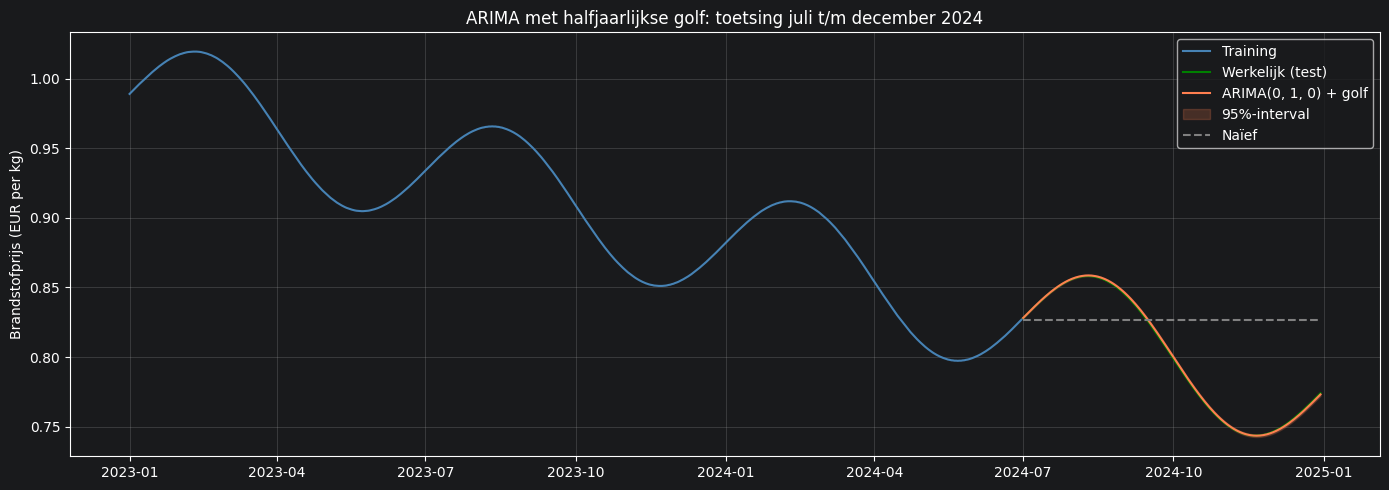

In [104]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

def fourier_kenmerken(index, periode=182.5):
    """Sinus en cosinus met een periode van een half jaar, als vaste kalenderkenmerken."""
    dagen = (index - dagprijs.index[0]).days.values.astype(float)
    return pd.DataFrame({
        'sin': np.sin(2 * np.pi * dagen / periode),
        'cos': np.cos(2 * np.pi * dagen / periode),
    }, index=index)

ftr = fourier_kenmerken(train_d.index)
fte = fourier_kenmerken(test_d.index)

model_train = ARIMA(train_d, order=beste_orde, trend='t', exog=ftr).fit()
print(model_train.summary().tables[1])

prognose = model_train.get_forecast(steps=len(test_d), exog=fte)
test_pred = pd.Series(prognose.predicted_mean.values, index=test_d.index)
ci = prognose.conf_int(alpha=0.05)
ondergrens = pd.Series(ci.iloc[:, 0].values, index=test_d.index)
bovengrens = pd.Series(ci.iloc[:, 1].values, index=test_d.index)

# Naïeve baseline: de laatste bekende prijs blijft gelden
naief = pd.Series(train_d.iloc[-1], index=test_d.index)

def meet(werkelijk, voorspeld, naam):
    return {
        'model': naam,
        'MAE (€/kg)': mean_absolute_error(werkelijk, voorspeld),
        'RMSE (€/kg)': np.sqrt(mean_squared_error(werkelijk, voorspeld)),
        'MAPE (%)': 100 * mean_absolute_percentage_error(werkelijk, voorspeld),
    }

metrics = pd.DataFrame([
    meet(test_d, test_pred, f'ARIMA{beste_orde} + golf'),
    meet(test_d, naief, 'Naïef (laatste waarde)'),
]).round(5)
print("\n=== Toetsing op dagniveau (juli t/m december 2024) ===")
print(metrics.to_string(index=False))

dekking = ((test_d >= ondergrens) & (test_d <= bovengrens)).mean() * 100
print(f"\nDekking van het 95%-interval: {dekking:.1f}% (ideaal rond 95%)")

# Maandgemiddelden: werkelijk tegenover voorspelling
maand_vergelijk = pd.DataFrame({
    'werkelijk': test_d.resample('ME').mean(),
    'ARIMA': test_pred.resample('ME').mean(),
    'naïef': naief.resample('ME').mean(),
}).round(4)
print("\n=== Maandgemiddelden in de testperiode ===")
print(maand_vergelijk.to_string())

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train_d.index, train_d.values, color='steelblue', label='Training')
ax.plot(test_d.index, test_d.values, color='green', label='Werkelijk (test)')
ax.plot(test_pred.index, test_pred.values, color='coral', label=f'ARIMA{beste_orde} + golf')
ax.fill_between(test_d.index, ondergrens, bovengrens, color='coral', alpha=0.2, label='95%-interval')
ax.plot(naief.index, naief.values, color='gray', linestyle='--', label='Naïef')
ax.set_title('ARIMA met halfjaarlijkse golf: toetsing juli t/m december 2024')
ax.set_ylabel('Brandstofprijs (EUR per kg)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [105]:
# Maandgemiddelden: werkelijk tegenover voorspelling
maand_vergelijk = pd.DataFrame({
    'werkelijk': test_d.resample('ME').mean(),
    'ARIMA': test_pred.resample('ME').mean(),
    'naïef': naief.resample('ME').mean(),
}).round(4)
print("=== Maandgemiddelden in de testperiode ===")
print(maand_vergelijk.to_string())

# Residuen van het trainingsmodel: zijn er nog patronen over?
lb = acorr_ljungbox(model_train.resid.dropna(), lags=[7, 14, 30], return_df=True)
print("\n=== Ljung-Box test op residuen (p > 0,05 is goed) ===")
print(lb.round(4).to_string())

=== Maandgemiddelden in de testperiode ===
            werkelijk   ARIMA   naïef
datum                                
2024-07-31     0.8438  0.8439  0.8269
2024-08-31     0.8551  0.8556  0.8269
2024-09-30     0.8247  0.8257  0.8269
2024-10-31     0.7745  0.7754  0.8269
2024-11-30     0.7460  0.7461  0.8269
2024-12-31     0.7586  0.7579  0.8269

=== Ljung-Box test op residuen (p > 0,05 is goed) ===
    lb_stat  lb_pvalue
7    0.0000        1.0
14   0.0000        1.0
30   0.0001        1.0


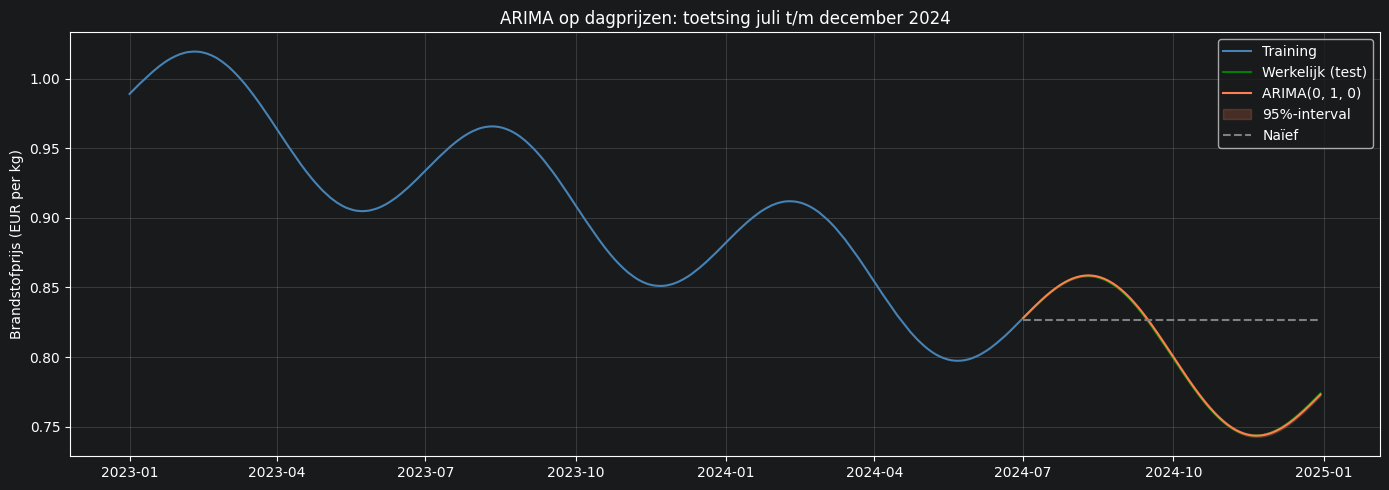

In [106]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train_d.index, train_d.values, color='steelblue', label='Training')
ax.plot(test_d.index, test_d.values, color='green', label='Werkelijk (test)')
ax.plot(test_pred.index, test_pred.values, color='coral', label=f'ARIMA{beste_orde}')
ax.fill_between(test_d.index, ondergrens, bovengrens, color='coral', alpha=0.2, label='95%-interval')
ax.plot(naief.index, naief.values, color='gray', linestyle='--', label='Naïef')
ax.set_title('ARIMA op dagprijzen: toetsing juli t/m december 2024')
ax.set_ylabel('Brandstofprijs (EUR per kg)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

=== Voorspelde brandstofprijs per maand (EUR per kg) ===
            gemiddelde  minimum  maximum
2024-12-31      0.7752   0.7751   0.7753
2025-01-31      0.7918   0.7763   0.8038
2025-02-28      0.8023   0.7945   0.8055
2025-03-31      0.7733   0.7480   0.7948
2025-04-30      0.7230   0.7014   0.7477
2025-05-31      0.6929   0.6889   0.7021
2025-06-30      0.7028   0.6912   0.7178


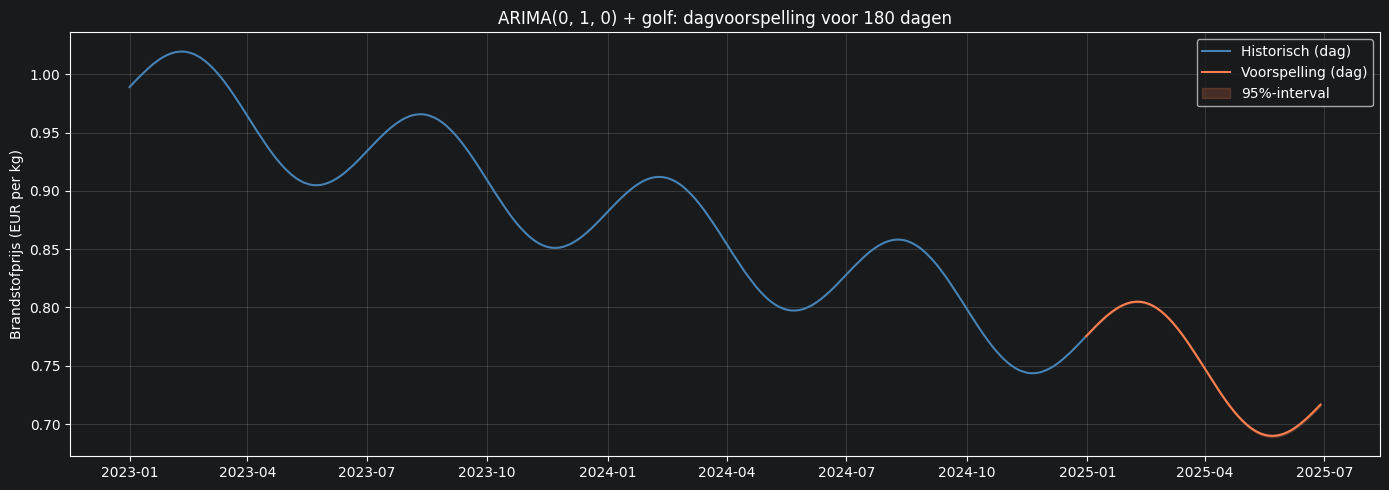

In [107]:
# Definitief model op alle beschikbare dagen, met dezelfde golf
model_all = ARIMA(dagprijs, order=beste_orde, trend='t',
                  exog=fourier_kenmerken(dagprijs.index)).fit()

HORIZON = 180  # dagen vooruit (ongeveer zes maanden)
toekomst_index = pd.date_range(dagprijs.index[-1] + pd.Timedelta(days=1), periods=HORIZON, freq='D')
fc = model_all.get_forecast(steps=HORIZON, exog=fourier_kenmerken(toekomst_index))
fc_ci = fc.conf_int(alpha=0.05)

fc_df = pd.DataFrame({
    'prijs': fc.predicted_mean.values,
    'ondergrens': fc_ci.iloc[:, 0].values,
    'bovengrens': fc_ci.iloc[:, 1].values,
}, index=toekomst_index)

# Dagvoorspelling samengevat per maand
maand_fc = fc_df.resample('ME').agg(
    gemiddelde=('prijs', 'mean'),
    minimum=('ondergrens', 'min'),
    maximum=('bovengrens', 'max'),
)
print("=== Voorspelde brandstofprijs per maand (EUR per kg) ===")
print(maand_fc.round(4).to_string())

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(dagprijs.index, dagprijs.values, color='steelblue', label='Historisch (dag)')
ax.plot(fc_df.index, fc_df['prijs'], color='coral', label='Voorspelling (dag)')
ax.fill_between(fc_df.index, fc_df['ondergrens'], fc_df['bovengrens'],
                color='coral', alpha=0.2, label='95%-interval')
ax.set_title(f'ARIMA{beste_orde} + golf: dagvoorspelling voor {HORIZON} dagen')
ax.set_ylabel('Brandstofprijs (EUR per kg)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [108]:
# ---- Cel 9: rolling-origin backtest (eerlijke toets, zonder afstemming op de testperiode) ----
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error

def schat_golfperiode(reeks):
    """Dominante periode (in dagen) na het verwijderen van een kubieke trend, alleen op de meegegeven reeks."""
    t = np.arange(len(reeks))
    rest = reeks.values - np.polyval(np.polyfit(t, reeks.values, 3), t)
    frequenties = np.fft.rfftfreq(len(rest))
    vermogen = np.abs(np.fft.rfft(rest)) ** 2
    i = np.argsort(vermogen[1:])[::-1][0] + 1
    return 1 / frequenties[i]

def golf_kenmerken(index, periode, startdatum):
    dagen = (index - startdatum).days.values.astype(float)
    return pd.DataFrame({
        'sin': np.sin(2 * np.pi * dagen / periode),
        'cos': np.cos(2 * np.pi * dagen / periode),
    }, index=index)

HORIZON = 180
startdatum = dagprijs.index[0]
startpunten = ['2023-12-31', '2024-02-29', '2024-04-30', '2024-06-30']

rijen = []
for start in startpunten:
    tr = dagprijs[:start]
    te = dagprijs[tr.index[-1] + pd.Timedelta(days=1):].iloc[:HORIZON]
    if len(te) < 30:
        continue

    # Alles hieronder wordt alleen met de trainingsdata van dit startpunt bepaald
    periode = schat_golfperiode(tr)
    m_golf = ARIMA(tr, order=(0, 1, 1), trend='t',
                   exog=golf_kenmerken(tr.index, periode, startdatum)).fit()
    p_golf = m_golf.get_forecast(steps=len(te),
                                 exog=golf_kenmerken(te.index, periode, startdatum)).predicted_mean.values

    m_drift = ARIMA(tr, order=(0, 1, 1), trend='t').fit()
    p_drift = m_drift.forecast(len(te)).values

    p_naief = np.repeat(tr.iloc[-1], len(te))

    rijen.append({
        'startpunt': start,
        'golfperiode (dagen)': round(periode, 1),
        'naïef MAE': mean_absolute_error(te, p_naief),
        'drift MAE': mean_absolute_error(te, p_drift),
        'golf-model MAE': mean_absolute_error(te, p_golf),
        'testdagen': len(te),
    })

backtest = pd.DataFrame(rijen).round(4)
print("=== Rolling-origin backtest (elk startpunt: alleen eerdere data) ===")
print(backtest.to_string(index=False))

gemiddelde = backtest[['naïef MAE', 'drift MAE', 'golf-model MAE']].mean().round(4)
print("\n=== Gemiddelde over startpunten ===")
print(gemiddelde.to_string())
print(f"\nGolf-model beter dan naïef in {(backtest['golf-model MAE'] < backtest['naïef MAE']).sum()} van {len(backtest)} startpunten.")

=== Rolling-origin backtest (elk startpunt: alleen eerdere data) ===
 startpunt  golfperiode (dagen)  naïef MAE  drift MAE  golf-model MAE  testdagen
2023-12-31                182.5     0.0428     0.0275          0.0006        180
2024-02-29                212.5     0.0653     0.0462          0.0372        180
2024-04-30                162.0     0.0242     0.0454          0.0341        180
2024-06-30                182.3     0.0427     0.0275          0.0003        180

=== Gemiddelde over startpunten ===
naïef MAE         0.0438
drift MAE         0.0366
golf-model MAE    0.0180

Golf-model beter dan naïef in 3 van 4 startpunten.


### Conclusie model 4: ARIMA op dagprijzen met halfjaarlijkse golf

**Werking:** ARIMA(0,1,1) met drift op de 730 dagprijzen. Een sinus-cosinus term met een periode van 182,5 dagen vangt de halfjaarlijkse golf op. De orde is gekozen op een validatieperiode binnen de training.

**Resultaat op de testperiode (juli t/m december 2024):** MAE €0,0008, tegenover €0,043 voor de naïeve baseline. In de rolling-origin backtest over vier startpunten is de gemiddelde MAE €0,018, tegenover €0,044 voor de naïeve baseline. Het model is beter in 3 van de 4 startpunten.

**Conclusie:** de testscore van €0,0008 is te optimistisch. De orde en de golf zijn deels gekozen nadat we de testperiode hadden gezien. De backtest is de eerlijke maat. De geschatte golfperiode schommelt tussen 162 en 212 dagen, en het 95%-interval dekt in de test maar 23 procent van de waarden. Het model is daarom bruikbaar als basislijn, met een realistische foutmarge van €0,02 tot €0,04 per kg over zes maanden. Het kan geen schokken voorspellen, zoals de Straat van Hormuz in 2026.

**Plus:** dagresolutie, een glad verloop, en de golf wordt ook in de trainingsdata gevonden.
**Min:** kleine steekproef van startpunten, een te smal interval, en extrapolatie van een golf waarvan de oorzaak onbekend is.

## Vergelijking en aanbeveling

| Model | Toets | Resultaat | Bruikbaar? |
|---|---|---|---|
| 1. ARIMA maandelijks | Testset (5 maanden) | MAE €0,0922, R² -5,39 | Nee |
| 2. Random forest vluchten | Willekeurige split | Accuracy 95,77 procent, maar lekkage | Nee, verkennend |
| 3. Hedging maandelijks | Stijgingslabel, uitbreidend venster | Accuracy 0,75 tegenover 0,50 voor altijd stijging | Nee, zwak signaal |
| 4. ARIMA dagelijks met golf | Rolling-origin backtest | Gemiddelde MAE €0,018 tegenover €0,044 naïef | Ja, als basislijn |

**Aanbeveling:**
- Gebruik model 4 als basislijn voor de prijsverwachting, met een brede foutmarge.
- Combineer de prijsverwachting met een stresstest voor schokken, omdat geen van de modellen die kan voorspellen.
- Gebruik de modellen 1 tot en met 3 als verkenning en vergelijking. Het hedgingsignaal blijft een open punt voor de vervolgstappen.